<a href="https://colab.research.google.com/github/akhilrajakhil113-ops/cyber-thread-detector/blob/main/House%20price%20predication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries Imported Successfully!
Upload your data.csv file


Saving train.csv to train (1).csv

Dataset Loaded Successfully!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  

Dataset Sh

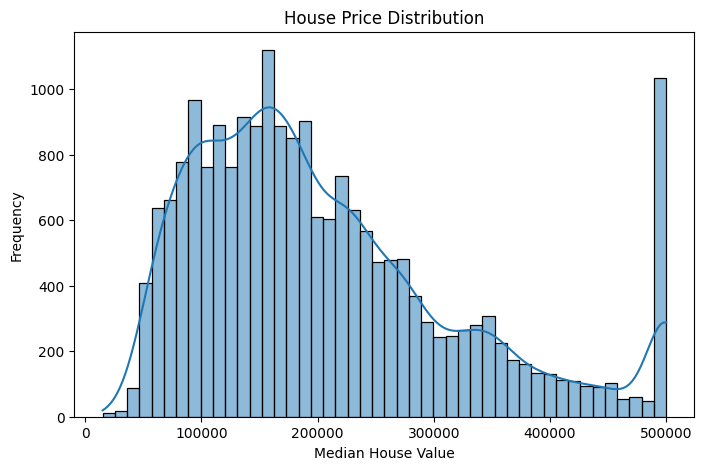

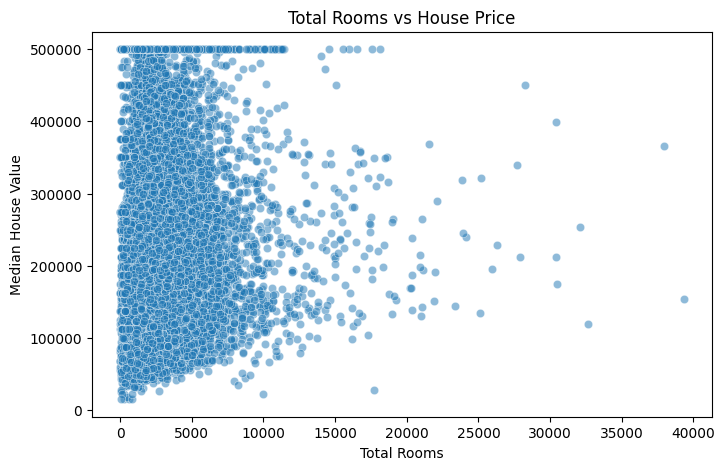

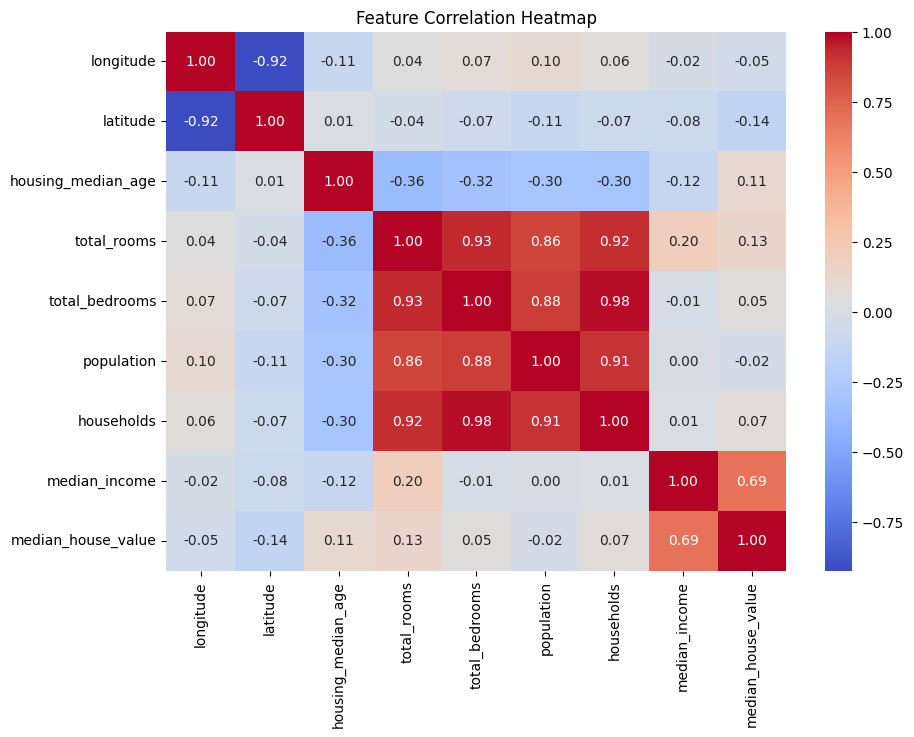


Training Data: (16512, 9)
Testing Data: (4128, 9)

Data Preprocessing Completed!

Linear Regression Model Trained Successfully!

House Price Predictions:
   Actual Price  Predicted Price
0       47700.0     54261.027690
1       45800.0    124430.917728
2      500001.0    255694.958282
3      218600.0    268208.010360
4      278000.0    262975.013606
5      158700.0    139811.882746
6      198200.0    290871.002705
7      157500.0    228470.455166
8      340000.0    256712.364401
9      446600.0    408129.437226

       MODEL PERFORMANCE
Mean Absolute Error: 50670.49
Mean Squared Error: 4908290571.35
Root Mean Squared Error: 70059.19
R2 Score: 0.6254


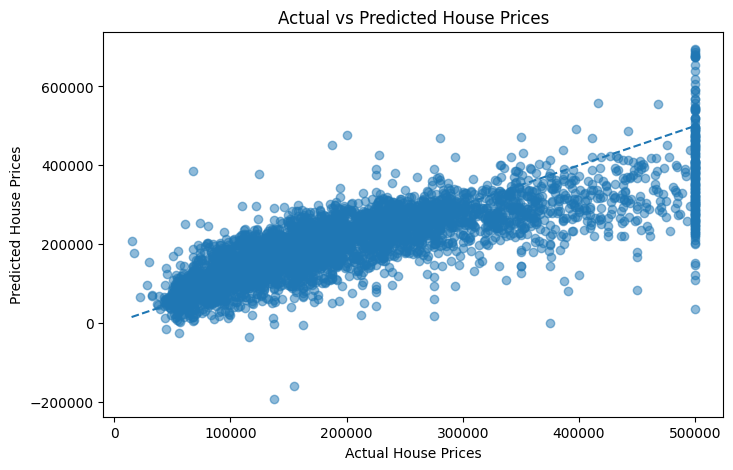


       PROJECT COMPLETED!

Project Files:
['model_performance.csv', 'cleaned_dataset.csv', 'README.md', 'graph4_actual_vs_predicted.png', 'graph2_rooms_vs_price.png', 'house_price_model.pkl', 'prediction_results.csv', 'graph1_price_distribution.png', 'graph3_correlation.png']



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

# ==========================================================
# HOUSE PRICE PREDICTION USING LINEAR REGRESSION
# COMPLETE DATA ANALYTICS PROJECT
# Dataset: California Housing Dataset (data.csv)
# ==========================================================

# 1. IMPORT LIBRARIES

!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import shutil

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries Imported Successfully!")

# 2. UPLOAD DATASET

print("Upload your data.csv file")

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("\nDataset Loaded Successfully!")
print(df.head())

# 3. DATASET INFORMATION

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

# 4. DATA CLEANING

# Remove Id if available
if "Id" in df.columns:
    df.drop("Id", axis=1, inplace=True)

# Remove rows with missing target values
df = df.dropna(subset=["median_house_value"])

# Separate input and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("\nData Cleaning Completed!")
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

# 5. CREATE PROJECT FOLDER

os.makedirs("House_Price_Project", exist_ok=True)

# 6. GRAPH 1 - HOUSE PRICE DISTRIBUTION

plt.figure(figsize=(8,5))

sns.histplot(
    df["median_house_value"],
    kde=True
)

plt.title("House Price Distribution")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.savefig(
    "House_Price_Project/graph1_price_distribution.png"
)

plt.show()

# 7. GRAPH 2 - TOTAL ROOMS VS HOUSE PRICE

plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df["total_rooms"],
    y=df["median_house_value"],
    alpha=0.5
)

plt.title("Total Rooms vs House Price")
plt.xlabel("Total Rooms")
plt.ylabel("Median House Value")

plt.savefig(
    "House_Price_Project/graph2_rooms_vs_price.png"
)

plt.show()

# 8. GRAPH 3 - CORRELATION HEATMAP

plt.figure(figsize=(10,7))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.savefig(
    "House_Price_Project/graph3_correlation.png"
)

plt.show()

# 9. SPLIT TRAINING AND TESTING DATA

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# 10. DATA PREPROCESSING

numeric_features = X_train.select_dtypes(
    include=np.number
).columns

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nData Preprocessing Completed!")

# 11. APPLY LINEAR REGRESSION

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")

# 12. PREDICT HOUSE PRICES

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nHouse Price Predictions:")
print(results.head(10))

# 13. MODEL PERFORMANCE EVALUATION

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n================================")
print("       MODEL PERFORMANCE")
print("================================")

print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# 14. GRAPH 4 - ACTUAL VS PREDICTED

plt.figure(figsize=(8,5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.savefig(
    "House_Price_Project/graph4_actual_vs_predicted.png"
)

plt.show()

# 15. SAVE TRAINED MODEL

joblib.dump(
    model,
    "House_Price_Project/house_price_model.pkl"
)

# 16. SAVE PREDICTION RESULTS

results.to_csv(
    "House_Price_Project/prediction_results.csv",
    index=False
)

# 17. SAVE PERFORMANCE METRICS

metrics = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ],

    "Value": [
        mae,
        mse,
        rmse,
        r2
    ]
})

metrics.to_csv(
    "House_Price_Project/model_performance.csv",
    index=False
)

# 18. SAVE CLEANED DATASET

df.to_csv(
    "House_Price_Project/cleaned_dataset.csv",
    index=False
)

# 19. CREATE README FILE

readme = """
# House Price Prediction Using Linear Regression

## Project Description
This project predicts house prices using Machine Learning.

## Dataset
California Housing Dataset.

## Algorithm
Linear Regression.

## Programming Language
Python.

## Platform
Google Colab.

## Libraries
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## Methodology
1. Dataset Collection
2. Data Cleaning
3. Data Preprocessing
4. Exploratory Data Analysis
5. Train-Test Split
6. Linear Regression
7. Model Prediction
8. Performance Evaluation
9. Data Visualization

## Evaluation Metrics
- Mean Absolute Error
- Mean Squared Error
- Root Mean Squared Error
- R2 Score

## Visualizations
1. House Price Distribution
2. Total Rooms vs House Price
3. Correlation Heatmap
4. Actual vs Predicted House Prices

## Conclusion
Linear Regression is used to predict house values
based on different housing features. The model is
evaluated using regression metrics and graphs.
"""

with open(
    "House_Price_Project/README.md",
    "w"
) as f:
    f.write(readme)

# 20. CREATE ZIP FILE

shutil.make_archive(
    "House_Price_Prediction_Project",
    "zip",
    "House_Price_Project"
)

print("\n================================")
print("       PROJECT COMPLETED!")
print("================================")

print("\nProject Files:")
print(os.listdir("House_Price_Project"))

print("\nDownloading Project ZIP...")

files.download(
    "House_Price_Prediction_Project.zip"
)

# ==========================================================
# END OF PROJECT
# ==========================================================
